# TAHAP 6 - DATASET YOLO26, SPLIT TRAIN:VAL:TEST (default 70:15:15, seed 0)

**Input** : `hasil/04_pengayaan` (gambar asli + varian + label) dan `hasil/05_fitur_bentuk/fitur_bentuk.csv`

**Output** : `hasil/06_dataset_yolo26_<train>_<val>_<test>/` (mis. `06_dataset_yolo26_70_15_15`). Nama folder mengikuti rasio split, jadi tiap preset punya folder sendiri dan **tidak saling menimpa**.

```
seg/  images/{train,val,test}  labels/{train,val,test}  data.yaml   -> yolo segment, yolo26n-seg.pt
det/  images/{train,val,test}  labels/{train,val,test}  data.yaml   -> yolo detect,  yolo26n.pt
test_robustness/  images/  labels/        (opsional)
laporan_split.csv  audit_split.txt
```

## Aturan anti-kebocoran data

1. Objek `terlalu_kecil` (tahap 5) dibuang; gambar tanpa objek tersisa ikut dibuang.
2. Yang dipisah adalah **kelompok foto asli** `(kelas, sumber)`: foto asli beserta **semua variannya** selalu berada di sisi yang sama.
3. Split **per kelas (stratified)** menurut jumlah foto asli, bukan total gambar + varian.
4. **Val dan test hanya berisi foto asli** (tanpa varian); augmentasi hanya menambah variasi training.
5. **Audit 3-sisi**: tidak ada kelompok yang berada di lebih dari satu sisi.
6. (opsional) **Robustness test**: varian goyang dan cahaya dibuat khusus dari foto test asli, disimpan terpisah, tidak masuk `data.yaml` utama.

| Preset | Status |
|---|---|
| `70-15-15` | **default**, disarankan untuk ~100-300 foto asli per kelas |
| `70-20-10` | boleh, bersyarat: val lebih besar tetapi test lebih kecil (kelas ~100 foto asli: test ~10 foto) |
| `80-10-10` | boleh, bersyarat: hanya bila foto asli per kelas sudah ratusan |

Letakkan notebook ini di `notebooks/`; modul pendukung ada di `scripts/`.

## 1. Setup dan import

In [1]:
import sys, os
from pathlib import Path

SCRIPTS = Path.cwd().resolve().parent / "scripts"
if not SCRIPTS.is_dir():
    SCRIPTS = Path.cwd().resolve()
sys.path.insert(0, str(SCRIPTS))

# Opsional: bila folder proyek bukan induk dari scripts/, hilangkan tanda # dan isi path-nya
# os.environ["PROYEK_ROOT"] = r"D:\rompi-cerdas-fin"

import random, shutil, zipfile
from collections import defaultdict

import cv2
import numpy as np
from IPython.display import Image, display

import bkpm
from config import CLASSES, D_AUG, D_FITUR, HASIL, ROOT
from util import baca_csv, baca_gambar, bersihkan, log, simpan_gambar, tabel, tulis_csv
from yolo_util import baca_label_seg, gambar_berlabel

TAHAP = "06_dataset_yolo26"
SISI = ("train", "val", "test")
PRESET = {"70-15-15": (0.15, 0.15), "70-20-10": (0.20, 0.10), "80-10-10": (0.10, 0.10)}   # (val, test)

print("Folder proyek :", ROOT)
print("Input pengayaan:", D_AUG / "manifest_pengayaan.csv", "| ada:", (D_AUG / "manifest_pengayaan.csv").exists())
print("Input fitur    :", D_FITUR / "fitur_bentuk.csv", "| ada:", (D_FITUR / "fitur_bentuk.csv").exists())

Folder proyek : C:\Projek\vestcare-dataset
Input pengayaan: C:\Projek\vestcare-dataset\hasil\04_pengayaan\manifest_pengayaan.csv | ada: True
Input fitur    : C:\Projek\vestcare-dataset\hasil\05_fitur_bentuk\fitur_bentuk.csv | ada: True


## 2. Parameter

Setara argumen CLI (`--preset`, `--val`, `--test`, `--seed`, `--val-dengan-varian`, `--test-dengan-varian`, `--buat-robustness-test`, `--zip`, `--keluaran`).

In [2]:
PRESET_PILIHAN = "70-15-15"   # "70-15-15" (default) | "70-20-10" | "80-10-10"
VAL = None                    # porsi val manual (mis. 0.2); menimpa preset
TEST = None                   # porsi test manual (mis. 0.1); menimpa preset
SEED = 0
VAL_DENGAN_VARIAN = False     # True = val ikut berisi varian pengayaan (default: hanya foto asli)
TEST_DENGAN_VARIAN = False    # True = test ikut berisi varian (TIDAK disarankan untuk angka resmi)
BUAT_ROBUSTNESS_TEST = False  # True = buat varian goyang/cahaya dari foto TEST asli, disimpan terpisah
BUAT_ZIP = False              # True = buat zip untuk Google Colab
KELUARAN = None               # None = hasil/06_dataset_yolo26_<rasio>; atau path folder bebas

val_frac, test_frac = PRESET[PRESET_PILIHAN]
if VAL is not None:
    val_frac = VAL
if TEST is not None:
    test_frac = TEST
if val_frac + test_frac >= 1:
    raise SystemExit(f"val+test ({val_frac + test_frac}) harus < 1 supaya train tidak kosong")

tr_pct, va_pct, te_pct = round((1 - val_frac - test_frac) * 100), round(val_frac * 100), round(test_frac * 100)
D_YOLO = Path(KELUARAN) if KELUARAN else HASIL / f"06_dataset_yolo26_{tr_pct}_{va_pct}_{te_pct}"
if not D_YOLO.is_absolute():
    D_YOLO = (Path.cwd() / D_YOLO).resolve()

print(f"Rasio train:val:test = {tr_pct}:{va_pct}:{te_pct} | seed {SEED}")
print("Folder keluaran :", D_YOLO)
print("Val berisi varian :", VAL_DENGAN_VARIAN, "| Test berisi varian:", TEST_DENGAN_VARIAN)
print("Robustness test   :", BUAT_ROBUSTNESS_TEST, "| Zip:", BUAT_ZIP)
if (PRESET_PILIHAN != "70-15-15" or VAL is not None or TEST is not None):
    print("\nPERHATIAN: bukan default 70-15-15. Pastikan ini pilihan sadar (lihat tabel preset di atas).")

Rasio train:val:test = 70:15:15 | seed 0
Folder keluaran : C:\Projek\vestcare-dataset\hasil\06_dataset_yolo26_70_15_15
Val berisi varian : False | Test berisi varian: False
Robustness test   : False | Zip: False


## 3. Fungsi inti

Sama dengan skrip asli: `muat_item`, `split_grup`, `tulis_dataset`, `tulis_data_yaml`, `audit_kebocoran`, `buat_robustness_test`. Fungsi membaca variabel `D_YOLO` dari sel parameter.

In [3]:
def muat_item():
    man = baca_csv(D_AUG / "manifest_pengayaan.csv")
    fitur = baca_csv(D_FITUR / "fitur_bentuk.csv")
    if not man or not fitur:
        raise SystemExit("jalankan notebook 04 dan 05 dulu")
    buang = defaultdict(set)                                    # file -> id objek yang dibuang
    for f in fitur:
        if f["qc"] != "ok":
            buang[f["file"]].add(int(f["id_objek"]))
    item = []
    for r in man:
        stem = r["file"].rsplit(".", 1)[0]
        asli = (D_AUG / "labels_seg" / f"{stem}.txt").read_text().splitlines()
        det = (D_AUG / "labels_det" / f"{stem}.txt").read_text().splitlines()
        ok = [i for i in range(len(asli)) if i not in buang[r["file"]]]
        if ok:
            item.append({**r, "stem": stem, "seg": [asli[i] for i in ok], "det": [det[i] for i in ok]})
    return item


def split_grup(grup, val_frac, test_frac, seed):
    """Split per KELOMPOK foto asli (kelas, sumber), stratified per kelas, seed tetap.
    Jaminan: test >= 1 kelompok bila kelasnya punya >= 2 kelompok, val >= 1 bila masih tersisa
    >= 2 kelompok setelah test, dan train tidak pernah kosong."""
    rng = random.Random(seed)
    sisi = {}
    for kelas in CLASSES:
        ids = sorted(s for (k, s) in grup if k == kelas)
        rng.shuffle(ids)
        n = len(ids)
        if n == 0:
            continue
        n_test = round(test_frac * n)
        n_val = round(val_frac * n)
        if n >= 2:
            n_test = max(1, n_test)
        if n - n_test >= 2:
            n_val = max(1, n_val)
        else:
            n_val = 0
        while n_test + n_val >= n and (n_val > 0 or n_test > 0):
            if n_val >= n_test and n_val > 0:
                n_val -= 1
            elif n_test > 0:
                n_test -= 1
            else:
                break
        for i, s in enumerate(ids):
            if i < n_test:
                sisi[(kelas, s)] = "test"
            elif i < n_test + n_val:
                sisi[(kelas, s)] = "val"
            else:
                sisi[(kelas, s)] = "train"
    return sisi


def tulis_dataset(grup, sisi, val_dengan_varian, test_dengan_varian):
    """Salin gambar+label ke D_YOLO/{seg,det}/images|labels/{train,val,test}."""
    jumlah = defaultdict(int)
    hanya_asli = {"val": not val_dengan_varian, "test": not test_dengan_varian}
    for (kelas, sumber), anggota in grup.items():
        s = sisi[(kelas, sumber)]
        for it in anggota:
            if s in hanya_asli and hanya_asli[s] and it["varian"] != "asli":
                continue
            for mode in ("seg", "det"):
                dst_i = D_YOLO / mode / "images" / s
                dst_l = D_YOLO / mode / "labels" / s
                dst_i.mkdir(parents=True, exist_ok=True)
                dst_l.mkdir(parents=True, exist_ok=True)
                shutil.copy2(D_AUG / "images" / it["file"], dst_i / it["file"])
                (dst_l / f"{it['stem']}.txt").write_text("\n".join(it[mode]) + "\n")
            jumlah[(kelas, s, "gambar")] += 1
            jumlah[(kelas, s, "objek")] += len(it["seg"])
            jumlah[(kelas, s, "foto_asli")] += it["varian"] == "asli"
    return jumlah


def tulis_data_yaml(val_frac, test_frac, test_robustness):
    nama = "\n".join(f"  {i}: {c}" for i, c in enumerate(CLASSES))
    train_pct = round((1 - val_frac - test_frac) * 100)
    for mode in ("seg", "det"):
        extra = "\ntest_robustness: ../test_robustness/images\n" if test_robustness else ""
        (D_YOLO / mode / "data.yaml").write_text(
            f"# dataset YOLO26 ({'segmentasi polygon' if mode == 'seg' else 'deteksi kotak'}), "
            f"split {train_pct}:{round(val_frac * 100)}:{round(test_frac * 100)} (train:val:test)\n"
            "# 'path' sengaja tidak ditulis: Ultralytics memakai folder data.yaml ini sebagai akar dataset\n"
            "# test_robustness (jika ada) BUKAN bagian dari evaluasi utama -- panggil model.val(split="
            "'test_robustness') terpisah, jangan dicampur dengan angka mAP test.\n"
            f"train: images/train\nval: images/val\ntest: images/test\n{extra}names:\n{nama}\n")


def audit_kebocoran(grup_sisi):
    """Pastikan tidak ada kelompok yang berada di >1 sisi (dicek pasangan demi pasangan)."""
    per_sisi = {s: {k for k, v in grup_sisi.items() if v == s} for s in SISI}
    bocor = {}
    for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
        irisan = per_sisi[a] & per_sisi[b]
        if irisan:
            bocor[(a, b)] = irisan
    return per_sisi, bocor


ROBUST_VARIAN = ["goyang", "cahaya_terang", "cahaya_gelap"]


def buat_robustness_test(grup, sisi):
    """Varian fotometrik (blur gerak = kamera goyang; terang/gelap) HANYA dari foto test ASLI."""
    rng = random.Random(0)
    jumlah = 0
    for mode_dir in ("images", "labels"):
        (D_YOLO / "test_robustness" / mode_dir).mkdir(parents=True, exist_ok=True)
    for (kelas, sumber), anggota in grup.items():
        if sisi[(kelas, sumber)] != "test":
            continue
        for it in anggota:
            if it["varian"] != "asli":
                continue
            img = baca_gambar(D_AUG / "images" / it["file"])
            if img is None:
                continue
            for v in ROBUST_VARIAN:
                if v == "goyang":
                    k = bkpm.kernel_gerak(rng.randint(9, 15), rng.uniform(0, 180))
                    im2 = bkpm.konvolusi(img, k)
                elif v == "cahaya_terang":
                    im2 = bkpm.brightness(img, rng.randint(35, 60))
                else:
                    im2 = bkpm.brightness(img, -rng.randint(35, 60))
                nv = f"{it['stem']}__{v}"
                simpan_gambar(D_YOLO / "test_robustness" / "images" / f"{nv}.jpg", im2, 95)
                (D_YOLO / "test_robustness" / "labels" / f"{nv}.txt").write_text("\n".join(it["seg"]) + "\n")
                jumlah += 1
    return jumlah


def tampil(img, maks=1100):
    h, w = img.shape[:2]
    s = min(1.0, maks / max(h, w))
    if s < 1.0:
        img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    display(Image(data=cv2.imencode(".png", img)[1].tobytes()))


def tampil_baris(daftar, tinggi=190, per_baris=4):
    """daftar = [(citra BGR, teks)]"""
    for i in range(0, len(daftar), per_baris):
        ubin = []
        for im, teks in daftar[i:i + per_baris]:
            s = tinggi / im.shape[0]
            t = cv2.resize(im, (max(1, int(im.shape[1] * s)), tinggi), interpolation=cv2.INTER_AREA)
            cv2.putText(t, teks, (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0, 0, 0), 3, cv2.LINE_AA)
            cv2.putText(t, teks, (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            ubin.append(t)
        tampil(np.hstack(ubin))

print("fungsi siap")

fungsi siap


## 4. Muat item dan buang objek `terlalu_kecil`

Objek ber-`qc` bukan `ok` dibuang dari label; gambar yang tidak punya objek tersisa dibuang seluruhnya.

In [4]:
man = baca_csv(D_AUG / "manifest_pengayaan.csv")
fitur = baca_csv(D_FITUR / "fitur_bentuk.csv")
item = muat_item()

n_obj_total = len(fitur)
n_obj_buang = sum(f["qc"] != "ok" for f in fitur)
print(f"Gambar di manifest      : {len(man)}")
print(f"Gambar dipakai          : {len(item)}  (dibuang karena tanpa objek tersisa: {len(man) - len(item)})")
print(f"Objek total             : {n_obj_total}")
print(f"Objek dibuang (qc)      : {n_obj_buang}")
tabel("Gambar dipakai per kelas", [{"kelas": k, "manifest": sum(r['kelas'] == k for r in man),
                                    "dipakai": sum(i['kelas'] == k for i in item)} for k in CLASSES],
      ["kelas", "manifest", "dipakai"])

Gambar di manifest      : 2944
Gambar dipakai          : 2944  (dibuang karena tanpa objek tersisa: 0)
Objek total             : 3854
Objek dibuang (qc)      : 14

Gambar dipakai per kelas
kelas   manifest  dipakai
pohon   561       561    
lubang  634       634    
orang   492       492    
motor   660       660    
mobil   597       597    


## 5. Kelompokkan per foto asli

Kunci kelompok = `(kelas, sumber)`: satu foto asli beserta semua variannya. Satuan pemisahan split adalah kelompok, bukan gambar.

In [5]:
grup = defaultdict(list)
for it in item:
    grup[(it["kelas"], it["sumber"])].append(it)

print(f"{'kelas':8s} {'kelompok':>9s} {'gambar':>7s} {'varian/kelompok':>16s}")
for k in CLASSES:
    gg = [v for (kk, _), v in grup.items() if kk == k]
    if gg:
        print(f"{k:8s} {len(gg):9d} {sum(len(v) for v in gg):7d} {sum(len(v) for v in gg) / len(gg):16.1f}")

contoh_key = next(iter(grup))
print(f"\nContoh kelompok {contoh_key}:")
for it in grup[contoh_key]:
    print(f"  {it['file']:50s} varian={it['varian']:9s} objek={len(it['seg'])}")

kelas     kelompok  gambar  varian/kelompok
pohon          187     561              3.0
lubang         317     634              2.0
orang          123     492              4.0
motor          220     660              3.0
mobil          199     597              3.0

Contoh kelompok ('pohon', 'pohon_primer-pohon-1'):
  pohon_primer-pohon-1.jpg                           varian=asli      objek=1
  pohon_primer-pohon-1__flip_h.jpg                   varian=flip_h    objek=1
  pohon_primer-pohon-1__cerah.jpg                    varian=cerah     objek=1


## 6. Split per kelompok (stratified per kelas)

Tabel menunjukkan berapa **kelompok foto asli** yang masuk train, val, dan test per kelas, beserta rasio sebenarnya (hasil pembulatan bisa sedikit berbeda dari rasio target).

In [6]:
sisi = split_grup(grup, val_frac, test_frac, SEED)

print(f"Rasio target train:val:test = {tr_pct}:{va_pct}:{te_pct} | seed {SEED}\n")
print(f"{'kelas':8s} {'n':>4s} {'train':>6s} {'val':>5s} {'test':>5s}   rasio nyata")
for k in CLASSES:
    n_s = {s: sum(1 for (kk, _), v in sisi.items() if kk == k and v == s) for s in SISI}
    n = sum(n_s.values())
    if n:
        print(f"{k:8s} {n:4d} {n_s['train']:6d} {n_s['val']:5d} {n_s['test']:5d}   "
              f"{100 * n_s['train'] / n:.0f}:{100 * n_s['val'] / n:.0f}:{100 * n_s['test'] / n:.0f}")
    if n and (n_s["test"] < 10):
        print(f"  ^ catatan: test {k} hanya {n_s['test']} foto asli; satu kesalahan prediksi bisa menggeser mAP kelas ini cukup jauh")

Rasio target train:val:test = 70:15:15 | seed 0

kelas       n  train   val  test   rasio nyata
pohon     187    131    28    28   70:15:15
lubang    317    221    48    48   70:15:15
orang     123     87    18    18   71:15:15
motor     220    154    33    33   70:15:15
mobil     199    139    30    30   70:15:15


## 7. Penulisan dataset

Salin gambar dan label ke `seg/` dan `det/`, tulis `data.yaml`. Val dan test hanya berisi foto asli kecuali dinyalakan lewat parameter.

> Sel ini **menghapus dan membuat ulang** folder keluaran (`D_YOLO`). Folder preset lain tidak disentuh.

In [7]:
bersihkan(D_YOLO)
jumlah = tulis_dataset(grup, sisi, VAL_DENGAN_VARIAN, TEST_DENGAN_VARIAN)
tulis_data_yaml(val_frac, test_frac, BUAT_ROBUSTNESS_TEST)
for mode in ("seg", "det"):
    n_i = {s: len(list((D_YOLO / mode / "images" / s).glob("*.jpg"))) if (D_YOLO / mode / "images" / s).is_dir() else 0 for s in SISI}
    print(f"{mode}: gambar {n_i}")
print("\nIsi seg/data.yaml:\n")
print((D_YOLO / "seg" / "data.yaml").read_text())

seg: gambar {'train': 2062, 'val': 157, 'test': 157}
det: gambar {'train': 2062, 'val': 157, 'test': 157}

Isi seg/data.yaml:

# dataset YOLO26 (segmentasi polygon), split 70:15:15 (train:val:test)
# 'path' sengaja tidak ditulis: Ultralytics memakai folder data.yaml ini sebagai akar dataset
# test_robustness (jika ada) BUKAN bagian dari evaluasi utama -- panggil model.val(split='test_robustness') terpisah, jangan dicampur dengan angka mAP test.
train: images/train
val: images/val
test: images/test
names:
  0: pohon
  1: lubang
  2: orang
  3: motor
  4: mobil



## 8. Laporan split (`laporan_split.csv`)

In [8]:
lap = []
for k in CLASSES:
    baris = {"kelas": k}
    for s in SISI:
        baris[f"foto_asli_{s}"] = jumlah[(k, s, "foto_asli")]
        baris[f"gambar_{s}"] = jumlah[(k, s, "gambar")]
        baris[f"objek_{s}"] = jumlah[(k, s, "objek")]
    lap.append(baris)
kol = ["kelas"] + [f"{m}_{s}" for m in ("foto_asli", "gambar", "objek") for s in SISI]
tulis_csv(D_YOLO / "laporan_split.csv", lap, kol)
tabel("Ringkasan split (train:val:test)", lap, kol)


Ringkasan split (train:val:test)
kelas   foto_asli_train  foto_asli_val  foto_asli_test  gambar_train  gambar_val  gambar_test  objek_train  objek_val  objek_test
pohon   131              28             28              393           28          28           393          28         28        
lubang  221              48             48              442           48          48           721          90         78        
orang   87               18             18              348           18          18           456          33         26        
motor   154              33             33              462           33          33           603          44         46        
mobil   139              30             30              417           30          30           471          32         32        


## 9. Audit kebocoran

Memastikan tidak ada kelompok foto asli yang berada di lebih dari satu sisi. Hasil ditulis ke `audit_split.txt`; bila ada kebocoran, sel berhenti dengan `AssertionError`.

In [9]:
per_sisi, bocor = audit_kebocoran(sisi)
n_tr, n_va, n_te = (len(per_sisi[s]) for s in SISI)
n_grup = n_tr + n_va + n_te
g_img_tr = sum(r["gambar_train"] for r in lap)
g_img_va = sum(r["gambar_val"] for r in lap)
g_img_te = sum(r["gambar_test"] for r in lap)

teks_audit = (
    f"preset={tr_pct}-{va_pct}-{te_pct} val_frac={val_frac} test_frac={test_frac} seed={SEED}\n"
    f"kelompok foto asli: train={n_tr} val={n_va} test={n_te} (total {n_grup})\n"
    f"rasio foto asli train:val:test = {n_tr / n_grup * 100:.1f}:{n_va / n_grup * 100:.1f}:{n_te / n_grup * 100:.1f}\n"
    f"gambar (termasuk varian di train): train={g_img_tr} val={g_img_va} test={g_img_te}\n"
    f"val berisi varian augmentasi: {VAL_DENGAN_VARIAN}\n"
    f"test berisi varian augmentasi: {TEST_DENGAN_VARIAN}\n"
    f"kelompok bocor (ada di >1 sisi): {sum(len(v) for v in bocor.values())}\n"
    + "".join(f"  {a} & {b}: {sorted(v)}\n" for (a, b), v in bocor.items())
)
print(teks_audit)
assert not bocor, "ada kelompok foto asli yang bocor ke lebih dari satu sisi!"
print("Audit lolos: tidak ada kebocoran antar sisi.")

preset=70-15-15 val_frac=0.15 test_frac=0.15 seed=0
kelompok foto asli: train=732 val=157 test=157 (total 1046)
rasio foto asli train:val:test = 70.0:15.0:15.0
gambar (termasuk varian di train): train=2062 val=157 test=157
val berisi varian augmentasi: False
test berisi varian augmentasi: False
kelompok bocor (ada di >1 sisi): 0

Audit lolos: tidak ada kebocoran antar sisi.


## 10. Robustness test (opsional)

Hanya dibuat bila `BUAT_ROBUSTNESS_TEST = True`. Varian **goyang** (blur gerak), **cahaya terang**, dan **cahaya gelap** dibuat dari foto test asli dan disimpan di `test_robustness/`. Skornya dilaporkan **terpisah** dari mAP test utama.

In [10]:
n_robust = 0
if BUAT_ROBUSTNESS_TEST:
    n_robust = buat_robustness_test(grup, sisi)
    print(f"{n_robust} varian dibuat -> {D_YOLO / 'test_robustness'}")
    rr = sorted((D_YOLO / "test_robustness" / "images").glob("*.jpg"))[:6]
    if rr:
        tampil_baris([(baca_gambar(p), p.stem.split("__")[-1]) for p in rr], per_baris=3)
else:
    print("BUAT_ROBUSTNESS_TEST = False, dilewati.")

teks_audit += (f"robustness test: {n_robust} varian dibuat dari foto test asli -> {D_YOLO}/test_robustness/ "
               "(laporkan TERPISAH dari mAP test utama)\n" if BUAT_ROBUSTNESS_TEST
               else "robustness test: tidak dibuat (BUAT_ROBUSTNESS_TEST = False)\n")
(D_YOLO / "audit_split.txt").write_text(teks_audit)

BUAT_ROBUSTNESS_TEST = False, dilewati.


392

## 11. Verifikasi independen dari isi folder

Pemeriksaan ulang langsung pada berkas hasil (bukan dari variabel di memori):

- tiap gambar punya label, tiap label punya gambar
- kunci kelompok (`<nama>` sebelum `__`) tidak muncul di lebih dari satu sisi
- val/test tidak berisi varian kecuali dinyalakan
- ID kelas di label ada di rentang `0..4`

In [11]:
masalah = []
kunci_per_sisi = {s: set() for s in SISI}
n_varian_di = {s: 0 for s in SISI}
for mode in ("seg", "det"):
    for s in SISI:
        di, dl = D_YOLO / mode / "images" / s, D_YOLO / mode / "labels" / s
        gambar = {p.stem for p in di.glob("*.jpg")} if di.is_dir() else set()
        label = {p.stem for p in dl.glob("*.txt")} if dl.is_dir() else set()
        if gambar != label:
            masalah.append((mode, s, f"gambar tanpa label: {len(gambar - label)}, label tanpa gambar: {len(label - gambar)}"))
        if mode == "seg":
            for st in gambar:
                kunci_per_sisi[s].add(st.split("__")[0])
                n_varian_di[s] += "__" in st
        for p in (dl.glob("*.txt") if dl.is_dir() else []):
            for baris in p.read_text().splitlines():
                if baris.strip() and not (0 <= int(baris.split()[0]) < len(CLASSES)):
                    masalah.append((mode, s, f"id kelas di luar rentang: {p.name}"))

for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    irisan = kunci_per_sisi[a] & kunci_per_sisi[b]
    if irisan:
        masalah.append(("kelompok", f"{a}&{b}", f"{len(irisan)} kunci ganda, mis. {sorted(irisan)[:3]}"))
if not VAL_DENGAN_VARIAN and n_varian_di["val"]:
    masalah.append(("seg", "val", f"{n_varian_di['val']} varian di val padahal VAL_DENGAN_VARIAN = False"))
if not TEST_DENGAN_VARIAN and n_varian_di["test"]:
    masalah.append(("seg", "test", f"{n_varian_di['test']} varian di test padahal TEST_DENGAN_VARIAN = False"))

print("Kelompok unik per sisi :", {s: len(kunci_per_sisi[s]) for s in SISI})
print("Berkas varian per sisi :", n_varian_di)
print("Masalah:", len(masalah))
for m in masalah[:20]:
    print("  ", m)
if not masalah:
    print("Semua pemeriksaan lolos.")

Kelompok unik per sisi : {'train': 732, 'val': 157, 'test': 157}
Berkas varian per sisi : {'train': 1330, 'val': 0, 'test': 0}
Masalah: 0
Semua pemeriksaan lolos.


## 12. Galeri per sisi

Contoh gambar dari train, val, dan test lengkap dengan polygon label (segmentasi). Train memuat varian; val dan test hanya foto asli.


== train: 2062 gambar ==


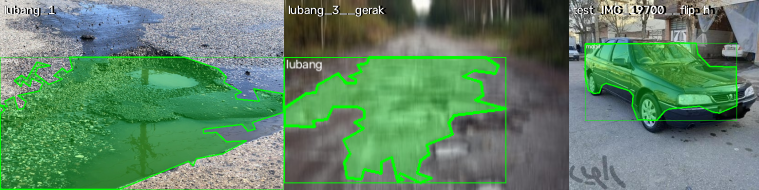

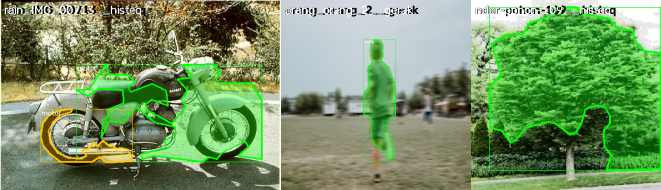


== val: 157 gambar ==


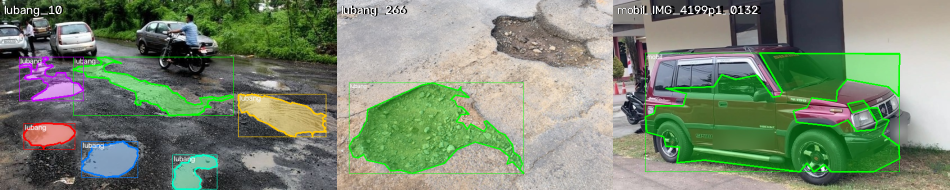

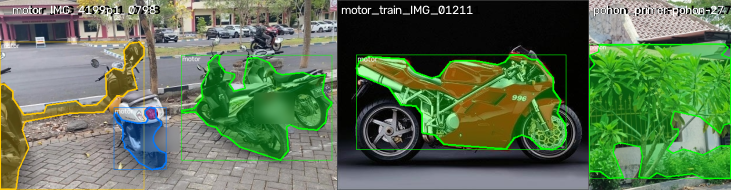


== test: 157 gambar ==


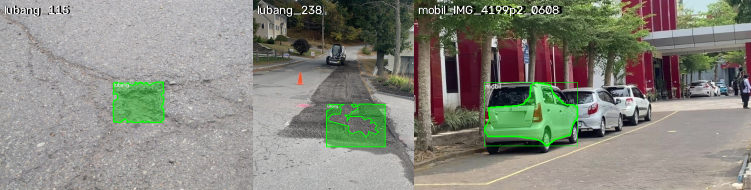

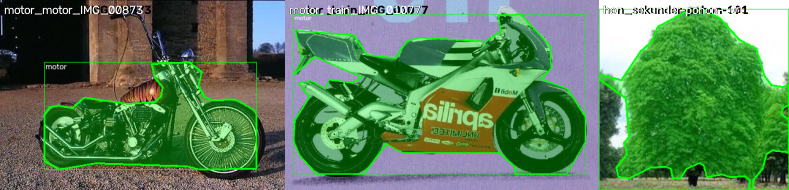

In [12]:
MAKS_GALERI = 6
for s in SISI:
    di, dl = D_YOLO / "seg" / "images" / s, D_YOLO / "seg" / "labels" / s
    fs = sorted(di.glob("*.jpg")) if di.is_dir() else []
    print(f"\n== {s}: {len(fs)} gambar ==")
    if not fs:
        continue
    galeri = []
    for p in fs[::max(1, len(fs) // MAKS_GALERI)][:MAKS_GALERI]:
        im = baca_gambar(p)
        h, w = im.shape[:2]
        lab = baca_label_seg(dl / f"{p.stem}.txt")
        polys = [(i, rel * [w, h]) for i, (_, rel) in enumerate(lab, 1)]
        kelas = CLASSES[lab[0][0]] if lab else "?"
        galeri.append((gambar_berlabel(im, polys, kelas), p.stem[-22:]))
    tampil_baris(galeri, per_baris=3)

## 13. Zip untuk Google Colab (opsional)

Hanya dibuat bila `BUAT_ZIP = True`. Zip disimpan di `hasil/<nama folder>.zip`.

In [13]:
if BUAT_ZIP:
    z = HASIL / f"{D_YOLO.name}.zip"
    with zipfile.ZipFile(z, "w", zipfile.ZIP_DEFLATED) as zf:
        for p in D_YOLO.rglob("*"):
            if p.is_file():
                zf.write(p, p.relative_to(D_YOLO))
    print(f"zip: {z}  ({z.stat().st_size / 1024 / 1024:.1f} MB)")
else:
    print("BUAT_ZIP = False, dilewati.")

BUAT_ZIP = False, dilewati.


## 14. Pemeriksaan akhir

In [16]:
log(TAHAP, f"selesai -> {D_YOLO}")
print("Isi folder keluaran:")
for p in sorted(D_YOLO.iterdir()):
    print("  ", p.name + ("/" if p.is_dir() else ""))
print("\nData.yaml seg :", D_YOLO / "seg" / "data.yaml")
print("Data.yaml det :", D_YOLO / "det" / "data.yaml")
print("\nLanjut ke notebook 06b_dataset_yolo26_70_15_15.ipynb (opsional)")

[06_dataset_yolo26] selesai -> C:\Projek\vestcare-dataset\hasil\06_dataset_yolo26_70_15_15
Isi folder keluaran:
   audit_split.txt
   det/
   laporan_split.csv
   seg/

Data.yaml seg : C:\Projek\vestcare-dataset\hasil\06_dataset_yolo26_70_15_15\seg\data.yaml
Data.yaml det : C:\Projek\vestcare-dataset\hasil\06_dataset_yolo26_70_15_15\det\data.yaml

Lanjut ke notebook 06b_dataset_yolo26_70_15_15.ipynb (opsional)
